In [ ]:
!pip install pyspark

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import *

import pandas as pd

In [ ]:
spark = SparkSession.builder \
    .appName("BigData_Sales_Analytics") \
    .master("local[*]") \
    .getOrCreate()

print("Spark is running!")
print("Spark version:", spark.version)

Spark is running!
Spark version: 4.0.5


In [ ]:
data = [
    (1, "Laptop", "Tunis", 1200),
    (2, "Phone", "Sfax", 800),
    (3, "Laptop", "Sousse", 1500),
    (4, "Tablet", "Tunis", 600),
    (5, "Phone", "Monastir", 900)
]

columns = ["id", "product", "region", "sales"]

df = spark.createDataFrame(data, columns)

df.printSchema()
df.show()

root
 |-- id: long (nullable = true)
 |-- product: string (nullable = true)
 |-- region: string (nullable = true)
 |-- sales: long (nullable = true)

+---+-------+--------+-----+
| id|product|  region|sales|
+---+-------+--------+-----+
|  1| Laptop|   Tunis| 1200|
|  2|  Phone|    Sfax|  800|
|  3| Laptop|  Sousse| 1500|
|  4| Tablet|   Tunis|  600|
|  5|  Phone|Monastir|  900|
+---+-------+--------+-----+



In [ ]:
df.select("product", "sales").show()

+-------+-----+
|product|sales|
+-------+-----+
| Laptop| 1200|
|  Phone|  800|
| Laptop| 1500|
| Tablet|  600|
|  Phone|  900|
+-------+-----+



In [ ]:
df.filter(df.sales>900).show()

+---+-------+------+-----+
| id|product|region|sales|
+---+-------+------+-----+
|  1| Laptop| Tunis| 1200|
|  3| Laptop|Sousse| 1500|
+---+-------+------+-----+



In [ ]:
df.groupBy("product") \
  .agg(sum("sales").alias("total_sales")) \
  .show()

+-------+-----------+
|product|total_sales|
+-------+-----------+
|  Phone|       1700|
| Laptop|       2700|
| Tablet|        600|
+-------+-----------+



In [ ]:
import pandas as pd

data = {
    "OrderID": [1, 2, 3, 4, 5],
    "Product": ["Laptop", "Phone", "Chair", "Laptop", "Table"],
    "Category": ["Electronics", "Electronics", "Furniture",
                 "Electronics", "Furniture"],
    "Region": ["Tunis", "Sfax", "Sousse", "Tunis", "Monastir"],
    "Quantity": [2, 3, 5, 1, 2],
    "Price": [1200, 800, 150, 1200, 300]
}

pdf = pd.DataFrame(data)

pdf.to_csv("sales.csv", index=False)

In [ ]:
df = spark.read.csv(
    "sales.csv",
    header=True,
    inferSchema=True
)

df.show()

+-------+-------+-----------+--------+--------+-----+
|OrderID|Product|   Category|  Region|Quantity|Price|
+-------+-------+-----------+--------+--------+-----+
|      1| Laptop|Electronics|   Tunis|       2| 1200|
|      2|  Phone|Electronics|    Sfax|       3|  800|
|      3|  Chair|  Furniture|  Sousse|       5|  150|
|      4| Laptop|Electronics|   Tunis|       1| 1200|
|      5|  Table|  Furniture|Monastir|       2|  300|
+-------+-------+-----------+--------+--------+-----+



In [ ]:
df.count()

5

In [ ]:
df.columns

['OrderID', 'Product', 'Category', 'Region', 'Quantity', 'Price']

In [ ]:
from pyspark.sql.functions import col
df.withColumn("Total",col("Quantity") * col("Price")).show()

+-------+-------+-----------+--------+--------+-----+-----+
|OrderID|Product|   Category|  Region|Quantity|Price|Total|
+-------+-------+-----------+--------+--------+-----+-----+
|      1| Laptop|Electronics|   Tunis|       2| 1200| 2400|
|      2|  Phone|Electronics|    Sfax|       3|  800| 2400|
|      3|  Chair|  Furniture|  Sousse|       5|  150|  750|
|      4| Laptop|Electronics|   Tunis|       1| 1200| 1200|
|      5|  Table|  Furniture|Monastir|       2|  300|  600|
+-------+-------+-----------+--------+--------+-----+-----+



In [ ]:
data = [
    (1, "Laptop", "Tunis", 2, 1200),
    (2, "Phone", "Sfax", 3, 800),
    (3, None, "Sousse", 5, 150),
    (4, "Laptop", "Tunis", 2, 1200),
    (5, "Tablet", None, 2, 300),
    (6, "Phone", "Monastir", None, 900)
]

columns = ["OrderID", "Product", "Region", "Quantity", "Price"]

df_dirty = spark.createDataFrame(data, columns)

df_dirty.show()

+-------+-------+--------+--------+-----+
|OrderID|Product|  Region|Quantity|Price|
+-------+-------+--------+--------+-----+
|      1| Laptop|   Tunis|       2| 1200|
|      2|  Phone|    Sfax|       3|  800|
|      3|   NULL|  Sousse|       5|  150|
|      4| Laptop|   Tunis|       2| 1200|
|      5| Tablet|    NULL|       2|  300|
|      6|  Phone|Monastir|    NULL|  900|
+-------+-------+--------+--------+-----+



In [ ]:
df_dirty.filter(col("Product").isNull()).show()

+-------+-------+------+--------+-----+
|OrderID|Product|Region|Quantity|Price|
+-------+-------+------+--------+-----+
|      3|   NULL|Sousse|       5|  150|
+-------+-------+------+--------+-----+



In [ ]:
from pyspark.sql.functions import col, sum

df_dirty.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df_dirty.columns
]).show()

+-------+-------+------+--------+-----+
|OrderID|Product|Region|Quantity|Price|
+-------+-------+------+--------+-----+
|      0|      1|     1|       1|    0|
+-------+-------+------+--------+-----+



In [ ]:
df_clean = df_dirty.dropna()

df_clean.show()

+-------+-------+------+--------+-----+
|OrderID|Product|Region|Quantity|Price|
+-------+-------+------+--------+-----+
|      1| Laptop| Tunis|       2| 1200|
|      2|  Phone|  Sfax|       3|  800|
|      4| Laptop| Tunis|       2| 1200|
+-------+-------+------+--------+-----+



In [ ]:
df_clean = df_clean.dropDuplicates()

df_clean.show()

+-------+-------+------+--------+-----+
|OrderID|Product|Region|Quantity|Price|
+-------+-------+------+--------+-----+
|      1| Laptop| Tunis|       2| 1200|
|      2|  Phone|  Sfax|       3|  800|
|      4| Laptop| Tunis|       2| 1200|
+-------+-------+------+--------+-----+



In [ ]:
df_clean = df_clean.dropDuplicates(["OrderID"])

In [ ]:
from pyspark.sql.functions import col

# Remove rows with missing important values
df_clean = df_dirty.dropna(subset=["Product", "Region", "Quantity"])

# Remove duplicate orders based on OrderID
df_clean = df_clean.dropDuplicates(["OrderID"])

# Display cleaned data
df_clean.show()

# Count rows
print("Rows before cleaning:", df_dirty.count())
print("Rows after cleaning:", df_clean.count())

+-------+-------+------+--------+-----+
|OrderID|Product|Region|Quantity|Price|
+-------+-------+------+--------+-----+
|      1| Laptop| Tunis|       2| 1200|
|      2|  Phone|  Sfax|       3|  800|
|      4| Laptop| Tunis|       2| 1200|
+-------+-------+------+--------+-----+

Rows before cleaning: 6
Rows after cleaning: 3


In [ ]:
from pyspark.sql.functions import col, sum as spark_sum, avg, count

# Create Total column
df_sales = df_clean.withColumn(
    "Total",
    col("Quantity") * col("Price")
)

# 1. Total revenue
df_sales.select(
    spark_sum("Total").alias("Total_Revenue")
).show()

# 2. Revenue by region
df_sales.groupBy("Region").agg(
    spark_sum("Total").alias("Revenue")
).show()

# 3. Revenue by product
df_sales.groupBy("Product").agg(
    spark_sum("Total").alias("Revenue")
).show()

# 4. Average order value
df_sales.select(
    avg("Total").alias("Average_Order_Value")
).show()

# 5. Number of orders
print("Number of orders:", df_sales.count())

+-------------+
|Total_Revenue|
+-------------+
|         7200|
+-------------+

+------+-------+
|Region|Revenue|
+------+-------+
| Tunis|   4800|
|  Sfax|   2400|
+------+-------+

+-------+-------+
|Product|Revenue|
+-------+-------+
|  Phone|   2400|
| Laptop|   4800|
+-------+-------+

+-------------------+
|Average_Order_Value|
+-------------------+
|             2400.0|
+-------------------+

Number of orders: 3


In [ ]:
import matplotlib.pyplot as plt

# Revenue by region
region_sales = df_sales.groupBy("Region").agg(
    spark_sum("Total").alias("Revenue")
)

# Convert Spark DataFrame to Pandas
region_pdf = region_sales.toPandas()

print(region_pdf)

  Region  Revenue
0  Tunis     4800
1   Sfax     2400


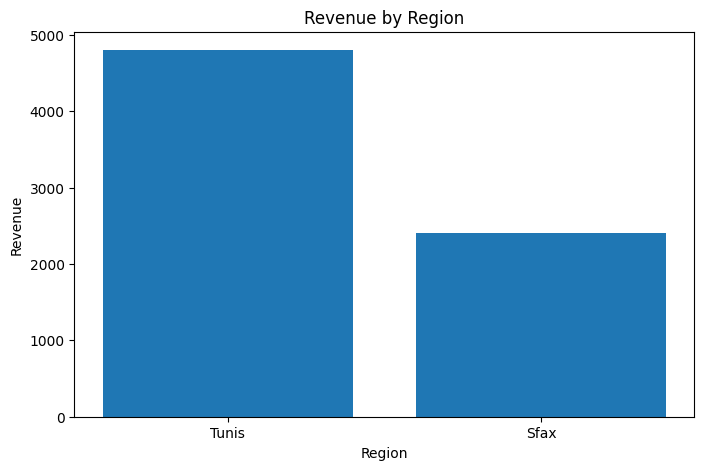

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(region_pdf["Region"], region_pdf["Revenue"])

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")

plt.show()

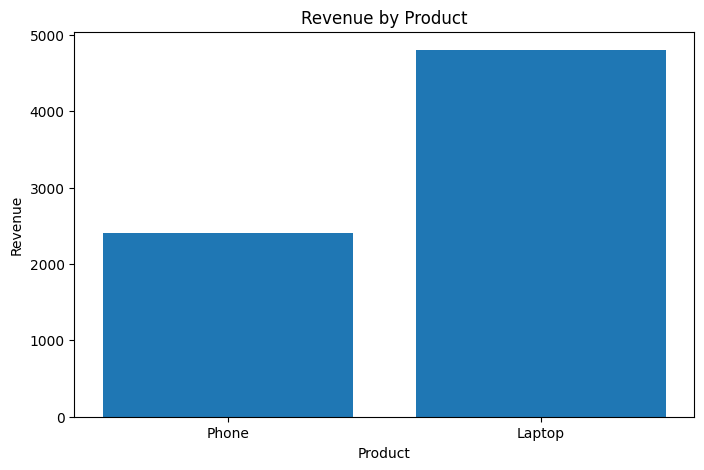

In [ ]:
product_pdf = df_sales.groupBy("Product").agg(
    spark_sum("Total").alias("Revenue")
).toPandas()

plt.figure(figsize=(8, 5))

plt.bar(product_pdf["Product"], product_pdf["Revenue"])

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue")

plt.show()

In [ ]:
df_sales.write \
    .mode("overwrite") \
    .parquet("sales_parquet")

In [ ]:
df_parquet = spark.read.parquet("sales_parquet")

df_parquet.show()
df_parquet.printSchema()

+-------+-------+------+--------+-----+-----+
|OrderID|Product|Region|Quantity|Price|Total|
+-------+-------+------+--------+-----+-----+
|      1| Laptop| Tunis|       2| 1200| 2400|
|      2|  Phone|  Sfax|       3|  800| 2400|
|      4| Laptop| Tunis|       2| 1200| 2400|
+-------+-------+------+--------+-----+-----+

root
 |-- OrderID: long (nullable = true)
 |-- Product: string (nullable = true)
 |-- Region: string (nullable = true)
 |-- Quantity: long (nullable = true)
 |-- Price: long (nullable = true)
 |-- Total: long (nullable = true)



Sales data:
+-------+-------+-----------+--------+--------+-----+-----+
|OrderID|Product|   Category|  Region|Quantity|Price|Total|
+-------+-------+-----------+--------+--------+-----+-----+
|      1| Laptop|Electronics|   Tunis|       2| 1200| 2400|
|      2|  Phone|Electronics|    Sfax|       3|  800| 2400|
|      3|  Chair|  Furniture|  Sousse|       5|  150|  750|
|      4| Laptop|Electronics|   Tunis|       1| 1200| 1200|
|      5|  Table|  Furniture|Monastir|       2|  300|  600|
+-------+-------+-----------+--------+--------+-----+-----+

Revenue by region:
+--------+-------+
|  Region|Revenue|
+--------+-------+
|Monastir|    600|
|   Tunis|   3600|
|    Sfax|   2400|
|  Sousse|    750|
+--------+-------+

Revenue by product:
+-------+-------+
|Product|Revenue|
+-------+-------+
|  Chair|    750|
|  Phone|   2400|
| Laptop|   3600|
|  Table|    600|
+-------+-------+



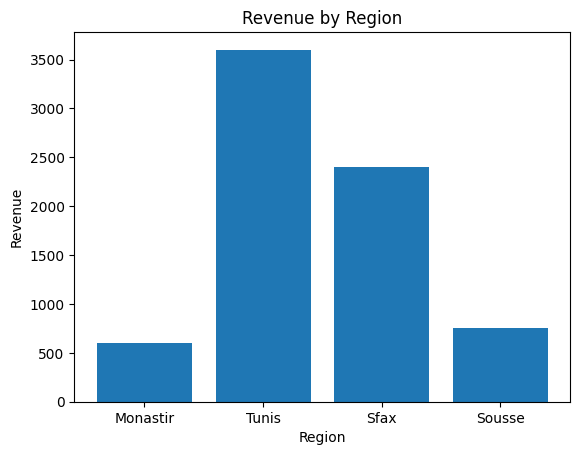

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, sum as spark_sum, avg
)
import matplotlib.pyplot as plt

# 1. Start Spark
spark = SparkSession.builder \
    .appName("BigData_Sales_Analytics") \
    .master("local[*]") \
    .getOrCreate()

# 2. Read CSV
df = spark.read.csv(
    "sales.csv",
    header=True,
    inferSchema=True
)

# 3. Clean data
df = df.dropna(
    subset=["OrderID", "Product", "Region", "Quantity", "Price"]
)

df = df.dropDuplicates(["OrderID"])

# 4. Calculate revenue
df = df.withColumn(
    "Total",
    col("Quantity") * col("Price")
)

# 5. Analyze revenue by region
region_sales = df.groupBy("Region").agg(
    spark_sum("Total").alias("Revenue")
)

# 6. Analyze revenue by product
product_sales = df.groupBy("Product").agg(
    spark_sum("Total").alias("Revenue")
)

# 7. Display results
print("Sales data:")
df.show()

print("Revenue by region:")
region_sales.show()

print("Revenue by product:")
product_sales.show()

# 8. Save results
df.write.mode("overwrite").parquet("sales_results")

# 9. Visualize
region_pdf = region_sales.toPandas()

plt.bar(region_pdf["Region"], region_pdf["Revenue"])
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.show()

In [ ]:
import pandas as pd
import random
from datetime import datetime, timedelta

random.seed(42)

products = {
    "Laptop": ("Electronics", 2500),
    "Phone": ("Electronics", 1200),
    "Tablet": ("Electronics", 900),
    "Chair": ("Furniture", 250),
    "Desk": ("Furniture", 500),
    "Headphones": ("Accessories", 150),
    "Keyboard": ("Accessories", 100)
}

regions = ["Tunis", "Sfax", "Sousse", "Monastir", "Gabes"]

data = []

start_date = datetime(2025, 1, 1)

for i in range(1, 10001):
    product = random.choice(list(products.keys()))
    category, price = products[product]

    order_date = start_date + timedelta(
        days=random.randint(0, 364)
    )

    quantity = random.randint(1, 5)

    data.append({
        "OrderID": i,
        "OrderDate": order_date.strftime("%Y-%m-%d"),
        "Product": product,
        "Category": category,
        "Region": random.choice(regions),
        "Quantity": quantity,
        "Price": price
    })

pdf = pd.DataFrame(data)

pdf.to_csv("sales.csv", index=False)

print("Dataset created successfully!")
print("Number of records:", len(pdf))

pdf.head()

Dataset created successfully!
Number of records: 10000


,OrderID,OrderDate,Product,Category,Region,Quantity,Price
0,1,2025-02-27,Headphones,Accessories,Sousse,1,150
1,2,2025-04-25,Phone,Electronics,Tunis,2,1200
2,3,2025-10-07,Headphones,Accessories,Gabes,1,150
3,4,2025-01-17,Chair,Furniture,Tunis,1,250
4,5,2025-04-30,Phone,Electronics,Gabes,5,1200


In [ ]:
df = spark.read.csv(
    "sales.csv",
    header=True,
    inferSchema=True
)

df.show(10)
df.printSchema()

print("Total records:", df.count())

+-------+----------+----------+-----------+--------+--------+-----+
|OrderID| OrderDate|   Product|   Category|  Region|Quantity|Price|
+-------+----------+----------+-----------+--------+--------+-----+
|      1|2025-02-27|Headphones|Accessories|  Sousse|       1|  150|
|      2|2025-04-25|     Phone|Electronics|   Tunis|       2| 1200|
|      3|2025-10-07|Headphones|Accessories|   Gabes|       1|  150|
|      4|2025-01-17|     Chair|  Furniture|   Tunis|       1|  250|
|      5|2025-04-30|     Phone|Electronics|   Gabes|       5| 1200|
|      6|2025-10-15|    Laptop|Electronics|   Gabes|       2| 2500|
|      7|2025-04-23|     Chair|  Furniture|   Gabes|       4|  250|
|      8|2025-01-04|    Tablet|Electronics|Monastir|       2|  900|
|      9|2025-05-23|    Tablet|Electronics|    Sfax|       2|  900|
|     10|2025-06-22|  Keyboard|Accessories|   Tunis|       1|  100|
+-------+----------+----------+-----------+--------+--------+-----+
only showing top 10 rows
root
 |-- OrderID: inte

In [ ]:
from google.colab import files
files.download("sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pyspark.sql.functions import (
    col, to_date, month, year,
    sum as spark_sum
)

df = df.withColumn(
    "OrderDate",
    to_date(col("OrderDate"), "yyyy-MM-dd")
)

In [ ]:
monthly_sales = df.groupBy(
    year("OrderDate").alias("Year"),
    month("OrderDate").alias("Month")
).agg(
    spark_sum(
        col("Quantity") * col("Price")
    ).alias("Monthly_Revenue")
).orderBy("Year", "Month")

monthly_sales.show(12)

+----+-----+---------------+
|Year|Month|Monthly_Revenue|
+----+-----+---------------+
|2025|    1|        2131000|
|2025|    2|        1779750|
|2025|    3|        1954100|
|2025|    4|        1767850|
|2025|    5|        2017900|
|2025|    6|        2104650|
|2025|    7|        2164750|
|2025|    8|        1922750|
|2025|    9|        2008200|
|2025|   10|        1977500|
|2025|   11|        1906900|
|2025|   12|        2213250|
+----+-----+---------------+



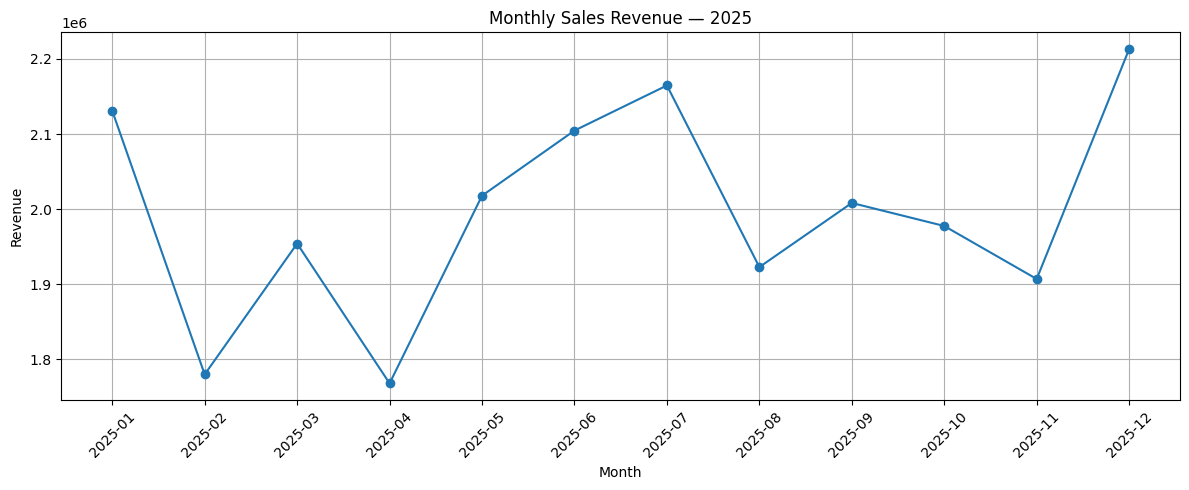

In [ ]:
import matplotlib.pyplot as plt

monthly_pdf = monthly_sales.toPandas()

monthly_pdf["Period"] = (
    monthly_pdf["Year"].astype(str)
    + "-"
    + monthly_pdf["Month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_pdf["Period"],
    monthly_pdf["Monthly_Revenue"],
    marker="o"
)

plt.title("Monthly Sales Revenue — 2025")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
monthly_sales.write \
    .mode("overwrite") \
    .parquet("monthly_sales_results")

In [ ]:
df.createOrReplaceTempView("sales")

In [ ]:
spark.sql("""
    SELECT *
    FROM sales
    LIMIT 10
""").show()

+-------+----------+----------+-----------+--------+--------+-----+
|OrderID| OrderDate|   Product|   Category|  Region|Quantity|Price|
+-------+----------+----------+-----------+--------+--------+-----+
|      1|2025-02-27|Headphones|Accessories|  Sousse|       1|  150|
|      2|2025-04-25|     Phone|Electronics|   Tunis|       2| 1200|
|      3|2025-10-07|Headphones|Accessories|   Gabes|       1|  150|
|      4|2025-01-17|     Chair|  Furniture|   Tunis|       1|  250|
|      5|2025-04-30|     Phone|Electronics|   Gabes|       5| 1200|
|      6|2025-10-15|    Laptop|Electronics|   Gabes|       2| 2500|
|      7|2025-04-23|     Chair|  Furniture|   Gabes|       4|  250|
|      8|2025-01-04|    Tablet|Electronics|Monastir|       2|  900|
|      9|2025-05-23|    Tablet|Electronics|    Sfax|       2|  900|
|     10|2025-06-22|  Keyboard|Accessories|   Tunis|       1|  100|
+-------+----------+----------+-----------+--------+--------+-----+



In [ ]:
spark.sql("""
    SELECT
        Region,
        SUM(Quantity * Price) AS Total_Revenue
    FROM sales
    GROUP BY Region
    ORDER BY Total_Revenue DESC
""").show()

+--------+-------------+
|  Region|Total_Revenue|
+--------+-------------+
|Monastir|      4984650|
|   Gabes|      4776750|
|    Sfax|      4738200|
|  Sousse|      4732450|
|   Tunis|      4716550|
+--------+-------------+



In [ ]:
spark.sql("""
    SELECT
        Product,
        SUM(Quantity) AS Total_Quantity
    FROM sales
    GROUP BY Product
    ORDER BY Total_Quantity DESC
""").show()

+----------+--------------+
|   Product|Total_Quantity|
+----------+--------------+
|     Chair|          4474|
|    Laptop|          4310|
|     Phone|          4292|
|      Desk|          4290|
|  Keyboard|          4184|
|Headphones|          4156|
|    Tablet|          4131|
+----------+--------------+



In [ ]:
spark.sql("""
    SELECT
        MONTH(OrderDate) AS Month,
        SUM(Quantity * Price) AS Monthly_Revenue
    FROM sales
    GROUP BY MONTH(OrderDate)
    ORDER BY Month
""").show()

+-----+---------------+
|Month|Monthly_Revenue|
+-----+---------------+
|    1|        2131000|
|    2|        1779750|
|    3|        1954100|
|    4|        1767850|
|    5|        2017900|
|    6|        2104650|
|    7|        2164750|
|    8|        1922750|
|    9|        2008200|
|   10|        1977500|
|   11|        1906900|
|   12|        2213250|
+-----+---------------+



In [ ]:
region_analysis = spark.sql("""
    SELECT
        Region,
        SUM(Quantity * Price) AS Revenue
    FROM sales
    GROUP BY Region
""")

region_analysis.write.mode("overwrite").parquet(
    "region_analysis"
)

In [ ]:
from pyspark.sql.functions import (
    col, sum as spark_sum, rank
)
from pyspark.sql.window import Window

product_revenue = df.groupBy("Product").agg(
    spark_sum(col("Quantity") * col("Price")).alias("Revenue")
)

In [ ]:
window_spec = Window.orderBy(col("Revenue").desc())

ranked_products = product_revenue.withColumn(
    "Rank",
    rank().over(window_spec)
)

ranked_products.show()

+----------+--------+----+
|   Product| Revenue|Rank|
+----------+--------+----+
|    Laptop|10775000|   1|
|     Phone| 5150400|   2|
|    Tablet| 3717900|   3|
|      Desk| 2145000|   4|
|     Chair| 1118500|   5|
|Headphones|  623400|   6|
|  Keyboard|  418400|   7|
+----------+--------+----+



In [ ]:
from pyspark.sql.functions import row_number

region_product = df.groupBy(
    "Region", "Product"
).agg(
    spark_sum(col("Quantity") * col("Price")).alias("Revenue")
)

window_region = Window.partitionBy("Region").orderBy(
    col("Revenue").desc()
)

top_products = region_product.withColumn(
    "Position",
    row_number().over(window_region)
)

top_products.filter(col("Position") == 1).show()

+--------+-------+-------+--------+
|  Region|Product|Revenue|Position|
+--------+-------+-------+--------+
|   Gabes| Laptop|2167500|       1|
|Monastir| Laptop|2155000|       1|
|    Sfax| Laptop|2212500|       1|
|  Sousse| Laptop|2147500|       1|
|   Tunis| Laptop|2092500|       1|
+--------+-------+-------+--------+



In [ ]:
from pyspark.sql.functions import month, year

monthly = df.groupBy(
    year("OrderDate").alias("Year"),
    month("OrderDate").alias("Month")
).agg(
    spark_sum(col("Quantity") * col("Price")).alias("Revenue")
)

window_month = Window.orderBy("Year", "Month").rowsBetween(
    Window.unboundedPreceding,
    Window.currentRow
)

monthly_cumulative = monthly.withColumn(
    "Cumulative_Revenue",
    spark_sum("Revenue").over(window_month)
).orderBy("Year", "Month")

monthly_cumulative.show()

+----+-----+-------+------------------+
|Year|Month|Revenue|Cumulative_Revenue|
+----+-----+-------+------------------+
|2025|    1|2131000|           2131000|
|2025|    2|1779750|           3910750|
|2025|    3|1954100|           5864850|
|2025|    4|1767850|           7632700|
|2025|    5|2017900|           9650600|
|2025|    6|2104650|          11755250|
|2025|    7|2164750|          13920000|
|2025|    8|1922750|          15842750|
|2025|    9|2008200|          17850950|
|2025|   10|1977500|          19828450|
|2025|   11|1906900|          21735350|
|2025|   12|2213250|          23948600|
+----+-----+-------+------------------+



In [ ]:
def extract_data(file_path):
    df = spark.read.csv(
        file_path,
        header=True,
        inferSchema=True
    )

    print("Data extracted successfully!")
    return df

In [ ]:
from pyspark.sql.functions import col

def transform_data(df):

    # Remove missing values
    df = df.dropna(
        subset=[
            "OrderID", "OrderDate", "Product",
            "Category", "Region", "Quantity", "Price"
        ]
    )

    # Remove duplicate orders
    df = df.dropDuplicates(["OrderID"])

    # Calculate total revenue
    df = df.withColumn(
        "Total",
        col("Quantity") * col("Price")
    )

    print("Data transformed successfully!")
    return df

In [ ]:
def load_data(df, output_path):

    df.write \
        .mode("overwrite") \
        .parquet(output_path)

    print("Data loaded successfully!")

In [ ]:
# Extract
df_raw = extract_data("sales.csv")

# Transform
df_transformed = transform_data(df_raw)

# Load
load_data(
    df_transformed,
    "output/sales_processed"
)

df_transformed.show(10)

Data extracted successfully!
Data transformed successfully!
Data loaded successfully!
+-------+----------+----------+-----------+--------+--------+-----+-----+
|OrderID| OrderDate|   Product|   Category|  Region|Quantity|Price|Total|
+-------+----------+----------+-----------+--------+--------+-----+-----+
|      1|2025-02-27|Headphones|Accessories|  Sousse|       1|  150|  150|
|      2|2025-04-25|     Phone|Electronics|   Tunis|       2| 1200| 2400|
|      3|2025-10-07|Headphones|Accessories|   Gabes|       1|  150|  150|
|      4|2025-01-17|     Chair|  Furniture|   Tunis|       1|  250|  250|
|      5|2025-04-30|     Phone|Electronics|   Gabes|       5| 1200| 6000|
|      6|2025-10-15|    Laptop|Electronics|   Gabes|       2| 2500| 5000|
|      7|2025-04-23|     Chair|  Furniture|   Gabes|       4|  250| 1000|
|      8|2025-01-04|    Tablet|Electronics|Monastir|       2|  900| 1800|
|      9|2025-05-23|    Tablet|Electronics|    Sfax|       2|  900| 1800|
|     10|2025-06-22|  Keyb

In [ ]:
from pyspark.sql.functions import col, sum as spark_sum

df_raw.select([
    spark_sum(col(c).isNull().cast("int")).alias(c)
    for c in df_raw.columns
]).show()

+-------+---------+-------+--------+------+--------+-----+
|OrderID|OrderDate|Product|Category|Region|Quantity|Price|
+-------+---------+-------+--------+------+--------+-----+
|      0|        0|      0|       0|     0|       0|    0|
+-------+---------+-------+--------+------+--------+-----+



In [ ]:
duplicates = df_raw.groupBy("OrderID").count().filter(
    col("count") > 1
)

duplicates.show()

print("Duplicate orders:", duplicates.count())

+-------+-----+
|OrderID|count|
+-------+-----+
+-------+-----+

Duplicate orders: 0


In [ ]:
invalid_data = df_raw.filter(
    (col("Price") <= 0) |
    (col("Quantity") <= 0)
)

invalid_data.show()

print("Invalid records:", invalid_data.count())

+-------+---------+-------+--------+------+--------+-----+
|OrderID|OrderDate|Product|Category|Region|Quantity|Price|
+-------+---------+-------+--------+------+--------+-----+
+-------+---------+-------+--------+------+--------+-----+

Invalid records: 0


In [ ]:
from pyspark.sql.functions import to_date

df_checked = df_raw.withColumn(
    "ParsedDate",
    to_date(col("OrderDate"), "yyyy-MM-dd")
)

invalid_dates = df_checked.filter(
    col("ParsedDate").isNull()
)

invalid_dates.show()

+-------+---------+-------+--------+------+--------+-----+----------+
|OrderID|OrderDate|Product|Category|Region|Quantity|Price|ParsedDate|
+-------+---------+-------+--------+------+--------+-----+----------+
+-------+---------+-------+--------+------+--------+-----+----------+



In [ ]:
def validate_data(df):

    total_rows = df.count()

    missing_rows = df.filter(
        col("OrderID").isNull() |
        col("Product").isNull() |
        col("Region").isNull() |
        col("Quantity").isNull() |
        col("Price").isNull()
    ).count()

    duplicate_rows = df.groupBy("OrderID").count().filter(
        col("count") > 1
    ).count()

    invalid_rows = df.filter(
        (col("Price") <= 0) |
        (col("Quantity") <= 0)
    ).count()

    print("Total rows:", total_rows)
    print("Rows with missing values:", missing_rows)
    print("Duplicate OrderIDs:", duplicate_rows)
    print("Rows with invalid prices/quantities:", invalid_rows)

    if missing_rows == 0 and duplicate_rows == 0 and invalid_rows == 0:
        print("DATA QUALITY: PASSED")
    else:
        print("DATA QUALITY: FAILED")

In [9]:
import os

HADOOP_HOME = "/content/hadoop-3.5.0"
HADOOP_CONF_DIR = f"{HADOOP_HOME}/etc/hadoop"

os.environ["HADOOP_HOME"] = HADOOP_HOME
os.environ["HADOOP_CONF_DIR"] = HADOOP_CONF_DIR
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"

In [10]:
core_site = """<?xml version="1.0"?>
<configuration>
    <property>
        <name>fs.defaultFS</name>
        <value>hdfs://localhost:9000</value>
    </property>
</configuration>
"""

with open(f"{HADOOP_CONF_DIR}/core-site.xml", "w") as f:
    f.write(core_site)

print("core-site.xml configured!")

core-site.xml configured!


In [11]:
hdfs_site = """<?xml version="1.0"?>
<configuration>
    <property>
        <name>dfs.replication</name>
        <value>1</value>
    </property>
    <property>
        <name>dfs.namenode.name.dir</name>
        <value>file:///content/hadoop_data/namenode</value>
    </property>
    <property>
        <name>dfs.datanode.data.dir</name>
        <value>file:///content/hadoop_data/datanode</value>
    </property>
</configuration>
"""

with open(f"{HADOOP_CONF_DIR}/hdfs-site.xml", "w") as f:
    f.write(hdfs_site)

print("hdfs-site.xml configured!")

hdfs-site.xml configured!


In [12]:
!cat /content/hadoop-3.5.0/etc/hadoop/core-site.xml
!cat /content/hadoop-3.5.0/etc/hadoop/hdfs-site.xml

<?xml version="1.0"?>
<configuration>
    <property>
        <name>fs.defaultFS</name>
        <value>hdfs://localhost:9000</value>
    </property>
</configuration>
<?xml version="1.0"?>
<configuration>
    <property>
        <name>dfs.replication</name>
        <value>1</value>
    </property>
    <property>
        <name>dfs.namenode.name.dir</name>
        <value>file:///content/hadoop_data/namenode</value>
    </property>
    <property>
        <name>dfs.datanode.data.dir</name>
        <value>file:///content/hadoop_data/datanode</value>
    </property>
</configuration>


In [13]:
import os

os.makedirs("/content/hadoop_data/namenode", exist_ok=True)
os.makedirs("/content/hadoop_data/datanode", exist_ok=True)

In [14]:
!hdfs namenode -format -force

[0.002s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
2026-11-17 20:02:55,344 INFO namenode.NameNode: STARTUP_MSG: 
/************************************************************
STARTUP_MSG: Starting NameNode
STARTUP_MSG:   host = 6cc105fab3f9/172.28.0.12
STARTUP_MSG:   args = [-format, -force]
STARTUP_MSG:   version = 3.5.0
STARTUP_MSG:   classpath = /content/hadoop-3.5.0/etc/hadoop:/content/hadoop-3.5.0/share/hadoop/common/lib/kerby-util-2.0.3.jar:/content/hadoop-3.5.0/share/hadoop/common/lib/hadoop-annotations-3.5.0.jar:/content/hadoop-3.5.0/share/hadoop/common/lib/commons-compress-1.26.1.jar:/content/hadoop-3.5.0/share/hadoop/common/lib/jsr305-3.0.2.jar:/content/hadoop-3.5.0/share/hadoop/common/lib/jetty-util-9.

In [15]:
!hdfs --daemon start namenode
!hdfs --daemon start datanode

In [16]:
!jps

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
4097 DataNode
4196 Jps
4042 NameNode


In [18]:
from google.colab import files
files.upload()

Saving sales.csv to sales.csv


{'sales.csv': b'OrderID,OrderDate,Product,Category,Region,Quantity,Price\n1,2025-02-27,Headphones,Accessories,Sousse,1,150\n2,2025-04-25,Phone,Electronics,Tunis,2,1200\n3,2025-10-07,Headphones,Accessories,Gabes,1,150\n4,2025-01-17,Chair,Furniture,Tunis,1,250\n5,2025-04-30,Phone,Electronics,Gabes,5,1200\n6,2025-10-15,Laptop,Electronics,Gabes,2,2500\n7,2025-04-23,Chair,Furniture,Gabes,4,250\n8,2025-01-04,Tablet,Electronics,Monastir,2,900\n9,2025-05-23,Tablet,Electronics,Sfax,2,900\n10,2025-06-22,Keyboard,Accessories,Tunis,1,100\n11,2025-02-19,Chair,Furniture,Sousse,3,250\n12,2025-05-16,Desk,Furniture,Monastir,1,500\n13,2025-03-05,Desk,Furniture,Tunis,4,500\n14,2025-05-31,Desk,Furniture,Sousse,5,500\n15,2025-04-09,Desk,Furniture,Tunis,1,500\n16,2025-04-27,Headphones,Accessories,Tunis,3,150\n17,2025-04-30,Keyboard,Accessories,Monastir,1,100\n18,2025-08-21,Tablet,Electronics,Sfax,3,900\n19,2025-07-01,Tablet,Electronics,Sousse,2,900\n20,2025-12-16,Headphones,Accessories,Gabes,1,150\n21,2025-

In [19]:
!hdfs dfs -mkdir -p /sales/data

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


In [20]:
!hdfs dfs -put -f /content/sales.csv /sales/data/

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


In [21]:
!hdfs dfs -ls /sales/data

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Found 1 items
-rw-r--r--   1 root supergroup     474805 2026-11-17 20:05 /sales/data/sales.csv


In [22]:
!hdfs dfs -cat /sales/data/sales.csv | head -5

[0.002s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
OrderID,OrderDate,Product,Category,Region,Quantity,Price
1,2025-02-27,Headphones,Accessories,Sousse,1,150
2,2025-04-25,Phone,Electronics,Tunis,2,1200
cat: Unable to write to output stream.


In [24]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum as spark_sum

spark = SparkSession.builder \
    .appName("BigData_Sales_Analytics") \
    .master("local[*]") \
    .getOrCreate()

print("Spark version:", spark.version)

Spark version: 4.0.5


In [25]:
hadoop_conf = spark.sparkContext._jsc.hadoopConfiguration()
hadoop_conf.set("fs.defaultFS", "hdfs://localhost:9000")

df_hdfs = spark.read.csv(
    "hdfs://localhost:9000/sales/data/sales.csv",
    header=True,
    inferSchema=True
)

df_hdfs.show(10)

+-------+----------+----------+-----------+--------+--------+-----+
|OrderID| OrderDate|   Product|   Category|  Region|Quantity|Price|
+-------+----------+----------+-----------+--------+--------+-----+
|      1|2025-02-27|Headphones|Accessories|  Sousse|       1|  150|
|      2|2025-04-25|     Phone|Electronics|   Tunis|       2| 1200|
|      3|2025-10-07|Headphones|Accessories|   Gabes|       1|  150|
|      4|2025-01-17|     Chair|  Furniture|   Tunis|       1|  250|
|      5|2025-04-30|     Phone|Electronics|   Gabes|       5| 1200|
|      6|2025-10-15|    Laptop|Electronics|   Gabes|       2| 2500|
|      7|2025-04-23|     Chair|  Furniture|   Gabes|       4|  250|
|      8|2025-01-04|    Tablet|Electronics|Monastir|       2|  900|
|      9|2025-05-23|    Tablet|Electronics|    Sfax|       2|  900|
|     10|2025-06-22|  Keyboard|Accessories|   Tunis|       1|  100|
+-------+----------+----------+-----------+--------+--------+-----+
only showing top 10 rows


In [29]:
import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/content/hadoop-3.5.0"
os.environ["HADOOP_CONF_DIR"] = "/content/hadoop-3.5.0/etc/hadoop"
os.environ["PATH"] += ":/content/hadoop-3.5.0/bin:/content/hadoop-3.5.0/sbin"

In [30]:
!hdfs --daemon start namenode
!hdfs --daemon start datanode
!sleep 3
!jps

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
8370 NameNode
8434 DataNode
8499 Jps
5374 SparkSubmit


In [31]:
!hdfs dfs -ls /sales/data

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Found 1 items
-rw-r--r--   1 root supergroup     474805 2026-11-17 20:05 /sales/data/sales.csv


In [32]:
df_hdfs = spark.read.csv(
    "hdfs://localhost:9000/sales/data/sales.csv",
    header=True,
    inferSchema=True
)

print("Total records:", df_hdfs.count())
df_hdfs.show(5)

Total records: 10000
+-------+----------+----------+-----------+------+--------+-----+
|OrderID| OrderDate|   Product|   Category|Region|Quantity|Price|
+-------+----------+----------+-----------+------+--------+-----+
|      1|2025-02-27|Headphones|Accessories|Sousse|       1|  150|
|      2|2025-04-25|     Phone|Electronics| Tunis|       2| 1200|
|      3|2025-10-07|Headphones|Accessories| Gabes|       1|  150|
|      4|2025-01-17|     Chair|  Furniture| Tunis|       1|  250|
|      5|2025-04-30|     Phone|Electronics| Gabes|       5| 1200|
+-------+----------+----------+-----------+------+--------+-----+
only showing top 5 rows


In [36]:
df_result = spark.read.parquet(
    "hdfs://localhost:9000/sales/results/region_revenue"
)

df_result.show()
df_result.printSchema()

+--------+-------+
|  Region|Revenue|
+--------+-------+
|Monastir|4984650|
|   Tunis|4716550|
|    Sfax|4738200|
|  Sousse|4732450|
|   Gabes|4776750|
+--------+-------+

root
 |-- Region: string (nullable = true)
 |-- Revenue: long (nullable = true)



In [37]:
df_result.agg(
    spark_sum("Revenue").alias("Total_Revenue")
).show()

+-------------+
|Total_Revenue|
+-------------+
|     23948600|
+-------------+



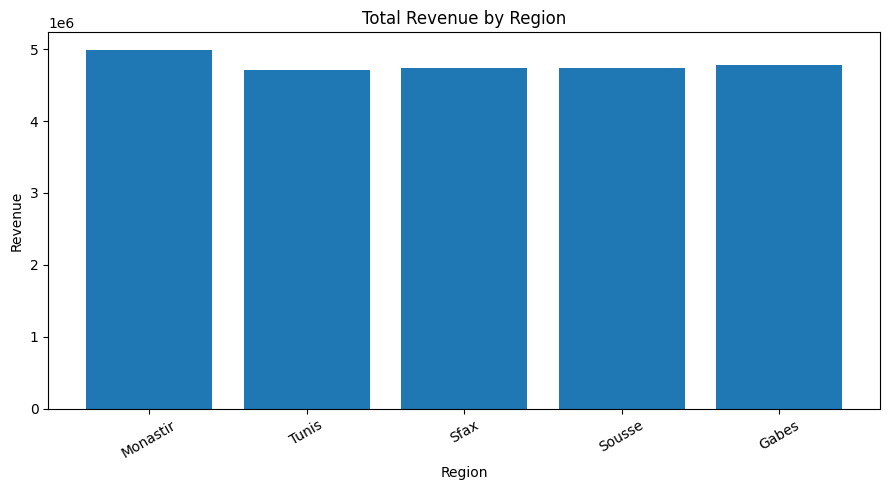

In [38]:
import matplotlib.pyplot as plt

df_result = spark.read.parquet(
    "hdfs://localhost:9000/sales/results/region_revenue"
)

region_pdf = df_result.toPandas()

plt.figure(figsize=(9, 5))
plt.bar(region_pdf["Region"], region_pdf["Revenue"])

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("revenue_by_region.png", dpi=300)
plt.show()

In [39]:
from google.colab import files
files.download("revenue_by_region.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>